
# AAI614: Data Science & its Applications

*Notebook 1.1: Data Visualization Libraries*

<a href="https://colab.research.google.com/github/harmanani/AAI614/blob/main/Week%201/Notebook1.1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*This notebook contains an excerpt from the [Python Data Science Handbook](http://shop.oreilly.com/product/0636920034919.do) by Jake VanderPlas; *

*The text is released under the [CC-BY-NC-ND license](https://creativecommons.org/licenses/by-nc-nd/3.0/us/legalcode), and code is released under the [MIT license](https://opensource.org/licenses/MIT). If you find this content useful, please consider supporting the work by [buying the book](http://shop.oreilly.com/product/0636920034919.do)!*

## Seaborn Versus Matplotlib

Here is an example of a simple random-walk plot in Matplotlib, using its classic plot formatting and colors.
We start with the typical imports:

In [1]:
import matplotlib.pyplot as plt
plt.style.use('classic')
%matplotlib inline
%pip install folium
import numpy as np
import pandas as pd


[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: C:\Users\Foody\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Now we create some random walk data:

In [2]:
# Create some data
rng = np.random.RandomState(0)
x = np.linspace(0, 10, 500)
y = np.cumsum(rng.randn(500, 6), 0)

And do a simple plot:

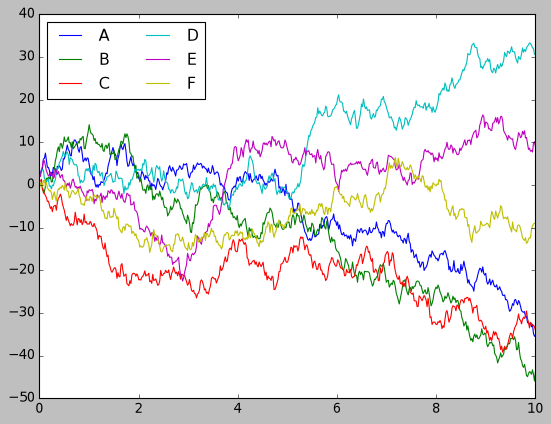

In [3]:
# Plot the data with Matplotlib defaults
plt.plot(x, y)
plt.legend('ABCDEF', ncol=2, loc='upper left');

### My experiment 1 — Matplotlib

I changed the color, line width, chart title, and grid to make the first random-walk series easier to read.

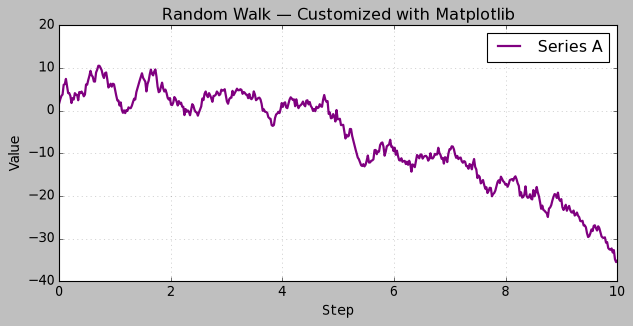

In [4]:
# Experiment 1: Change the appearance of a Matplotlib plot
plt.figure(figsize=(9, 4))
plt.plot(x, y[:, 0], color="purple", linewidth=2, label="Series A")
plt.title("Random Walk — Customized with Matplotlib")
plt.xlabel("Step")
plt.ylabel("Value")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Although the result contains all the information we'd like it to convey, it does so in a way that is not all that aesthetically pleasing, and even looks a bit old-fashioned in the context of 21st-century data visualization.

Now let's take a look at how it works with Seaborn.
As we will see, Seaborn has many of its own high-level plotting routines, but it can also overwrite Matplotlib's default parameters and in turn get even simple Matplotlib scripts to produce vastly superior output.
We can set the style by calling Seaborn's ``set()`` method.
By convention, Seaborn is imported as ``sns``:

In [5]:
import seaborn as sns
sns.set()

Now let's rerun the same two lines as before:

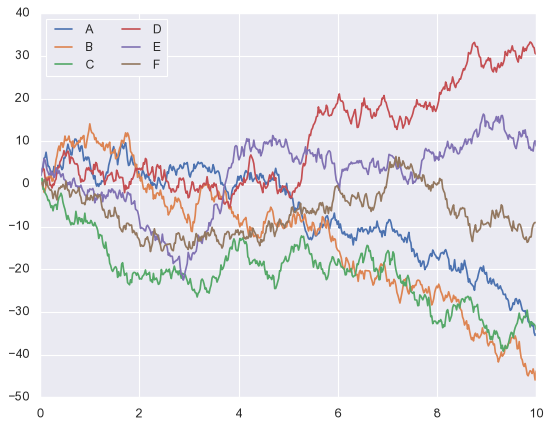

In [6]:
# same plotting code as above!
plt.plot(x, y)
plt.legend('ABCDEF', ncol=2, loc='upper left');

Ah, much better!

## Exploring Seaborn Plots

The main idea of Seaborn is that it provides high-level commands to create a variety of plot types useful for statistical data exploration, and even some statistical model fitting.

Let's take a look at a few of the datasets and plot types available in Seaborn. Note that all of the following *could* be done using raw Matplotlib commands (this is, in fact, what Seaborn does under the hood) but the Seaborn API is much more convenient.

### Histograms, KDE, and densities

Often in statistical data visualization, all you want is to plot histograms and joint distributions of variables.
We have seen that this is relatively straightforward in Matplotlib:

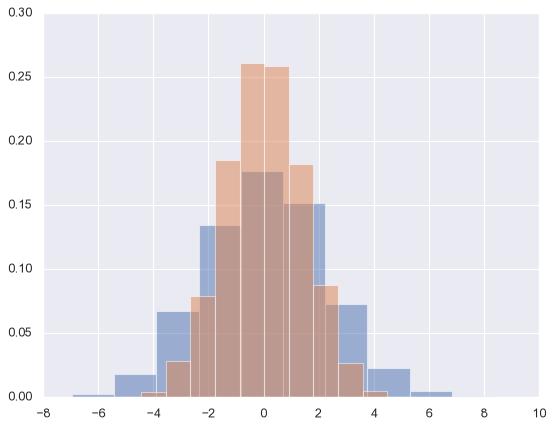

In [7]:
data = np.random.multivariate_normal([0, 0], [[5, 2], [2, 2]], size=2000)
data = pd.DataFrame(data, columns=['x', 'y'])

for col in 'xy':
    plt.hist(data[col], density=True, alpha=0.5)

Rather than a histogram, we can get a smooth estimate of the distribution using a kernel density estimation, which Seaborn does with ``sns.kdeplot``:

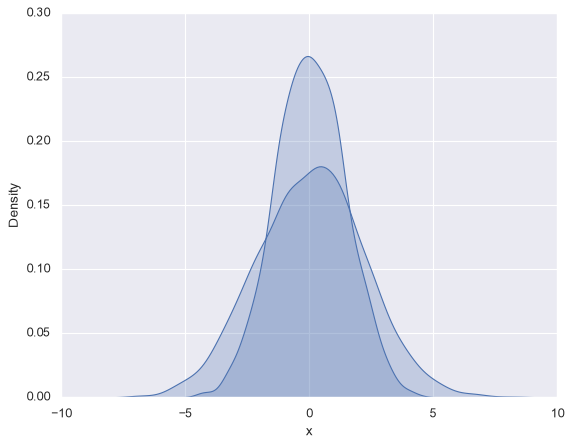

In [8]:
for col in 'xy':
    sns.kdeplot(data[col], fill=True)

Histograms and KDE can be combined using ``displot``:

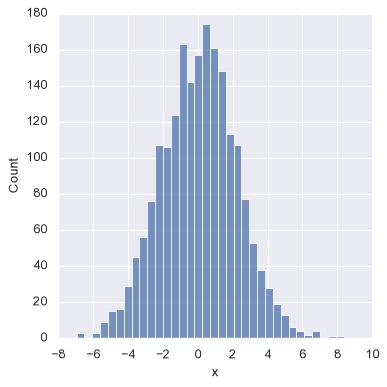

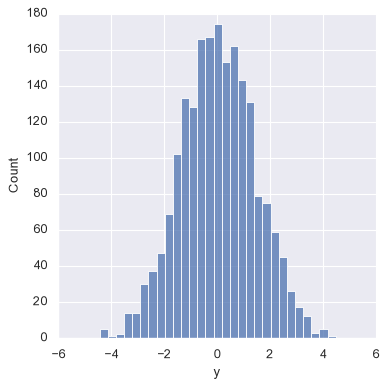

In [9]:
sns.displot(data['x'])
sns.displot(data['y']);

### My experiment 2 — Seaborn

I combined a histogram with a KDE density curve and changed the number of bins and chart color.

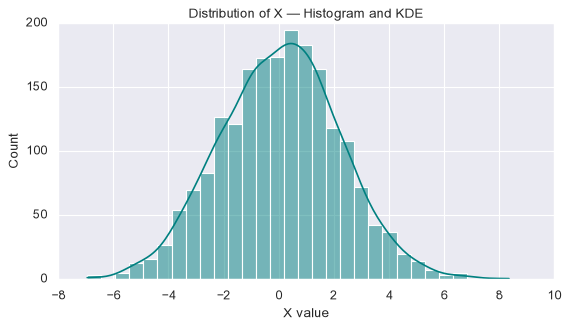

In [10]:
# Experiment 2: Combine histogram and KDE in Seaborn
plt.figure(figsize=(8, 4))
sns.histplot(data=data, x="x", bins=30, kde=True, color="teal")
plt.title("Distribution of X — Histogram and KDE")
plt.xlabel("X value")
plt.ylabel("Count")
plt.show()

If we pass the full two-dimensional dataset to ``kdeplot``, we will get a two-dimensional visualization of the data:

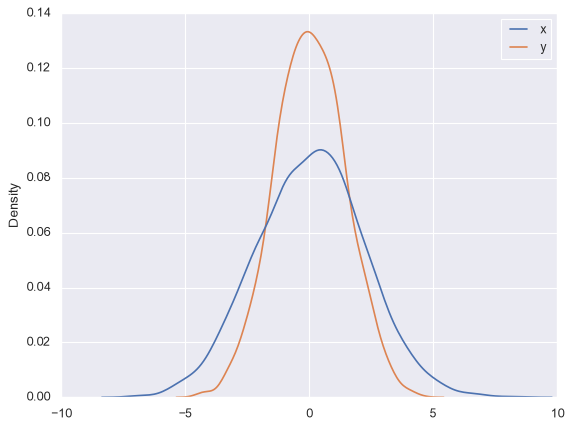

In [11]:
sns.kdeplot(data);

There are other parameters that can be passed to ``jointplot``—for example, we can use a hexagonally based histogram instead:

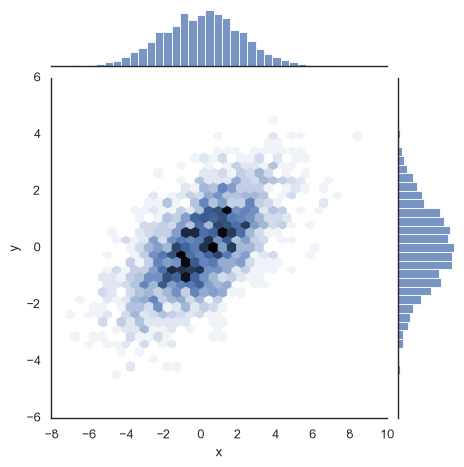

In [12]:
with sns.axes_style('white'):
    sns.jointplot(data=data, x="x", y="y", kind='hex')

### Pair plots

When you generalize joint plots to datasets of larger dimensions, you end up with *pair plots*. This is very useful for exploring correlations between multidimensional data, when you'd like to plot all pairs of values against each other.

We'll demo this with the well-known Iris dataset, which lists measurements of petals and sepals of three iris species:

In [13]:
import ssl

ssl._create_default_https_context = ssl._create_unverified_context

iris = sns.load_dataset("iris")
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Visualizing the multidimensional relationships among the samples is as easy as calling ``sns.pairplot``:

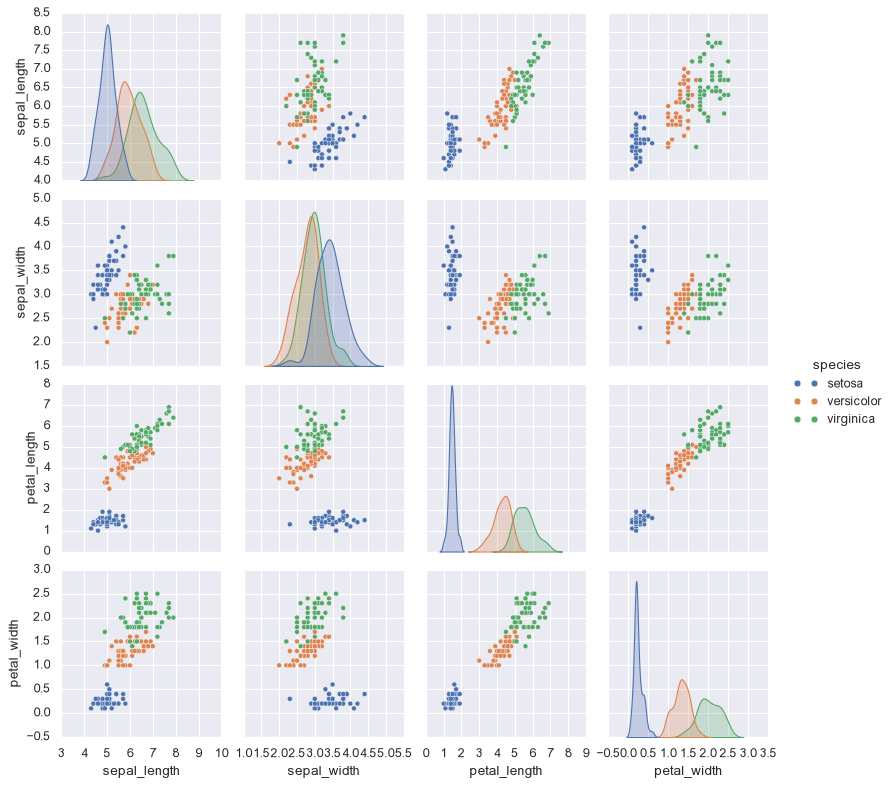

In [14]:
sns.pairplot(iris, hue='species', height=2.5);

### Faceted histograms

Sometimes the best way to view data is via histograms of subsets. Seaborn's ``FacetGrid`` makes this extremely simple.
We'll take a look at some data that shows the amount that restaurant staff receive in tips based on various indicator data:

In [15]:
tips = sns.load_dataset('tips')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


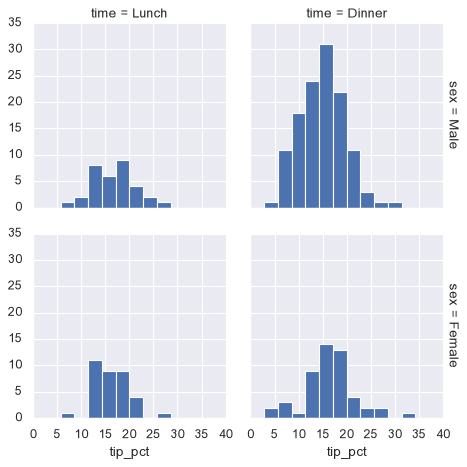

In [16]:
tips['tip_pct'] = 100 * tips['tip'] / tips['total_bill']

grid = sns.FacetGrid(tips, row="sex", col="time", margin_titles=True)
grid.map(plt.hist, "tip_pct", bins=np.linspace(0, 40, 15));

### Cat plots

Cat plots can be useful for this kind of visualization as well. This allows you to view the distribution of a parameter within bins defined by any other parameter:

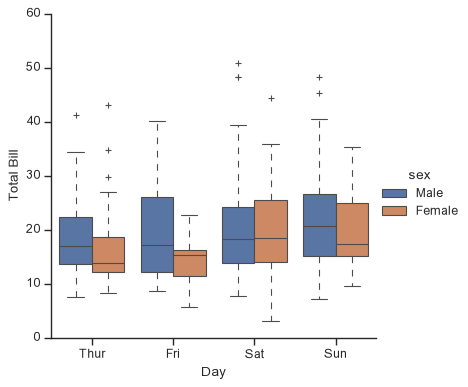

In [17]:
with sns.axes_style(style='ticks'):
    g = sns.catplot(x="day", y="total_bill", hue="sex", data=tips, kind="box")
    g.set_axis_labels("Day", "Total Bill");

### Bar plots

Time series can be plotted using ``sns.catplot``. In the following example, we'll use the Planets data that we first saw in [Aggregation and Grouping](03.08-Aggregation-and-Grouping.ipynb):

In [18]:
planets = sns.load_dataset('planets')
planets.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


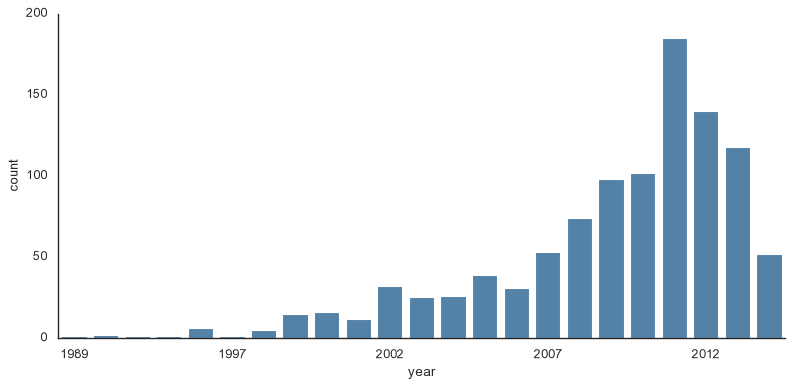

In [19]:
with sns.axes_style('white'):
    g = sns.catplot(x="year", data=planets, aspect=2, kind="count", color='steelblue')
    g.set_xticklabels(step=5)

We can learn more by looking at the *method* of discovery of each of these planets:

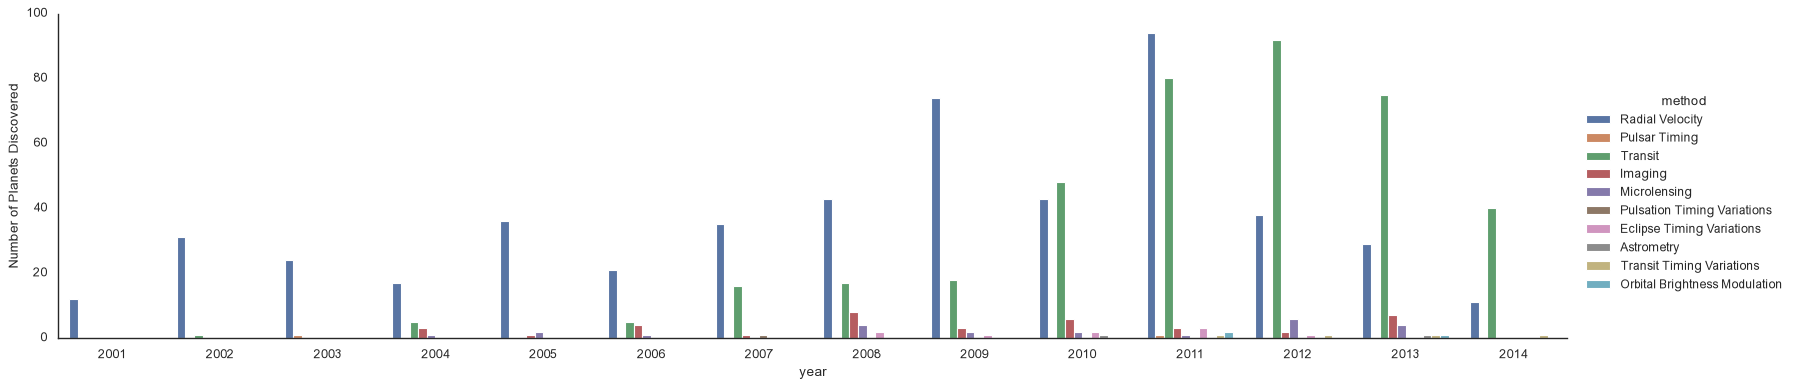

In [20]:
with sns.axes_style('white'):
    g = sns.catplot(x="year", data=planets, aspect=4.0, kind="count", hue="method", order=range(2001, 2015))
    g.set_ylabels('Number of Planets Discovered')

# Experiment with Folium

In [29]:
import folium

#Lebanon
Lebanon = folium.Map(location=(33.8735578, 35.863749))

In [30]:
Lebanon

In [31]:
Lebanon.save("index.html")

## Changing The tileset



The default tiles are set to OpenStreetMap, but a selection of tilesets are also built in.


In [24]:
folium.Map((33.8735578, 35.863749), tiles="cartodb positron")


C:\Users\Foody\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\folium\raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## Adding markers

In [25]:
m = folium.Map([33.8735578, 35.863749], zoom_start=10)

folium.Marker(
    location=[33.89305,35.47785],
    tooltip="LAU",
    popup="Lebanese American University",
    icon=folium.Icon(icon="cloud"),
).add_to(m)

folium.Marker(
    location=[34.11706,35.67413],
    tooltip="LAU",
    popup="Lebanese American University",
    icon=folium.Icon(color="green"),
).add_to(m)

m

### My experiment 3 — Folium

I created a map centered on Tripoli, Lebanon, increased the zoom level, and added a clickable marker.

In [26]:
# Experiment 3: Center the map on Tripoli and add a marker
tripoli_map = folium.Map(location=[34.4367, 35.8497], zoom_start=12)
folium.Marker(
    location=[34.4367, 35.8497],
    tooltip="Tripoli",
    popup="Tripoli, Lebanon",
    icon=folium.Icon(color="blue", icon="info-sign")
).add_to(tripoli_map)
tripoli_map

## GeoJSON/TopoJSON overlays

Folium supports both GeoJSON and TopoJSON data in various formats, such as urls, file paths and dictionaries.

In [27]:
import requests

m = folium.Map(tiles="cartodbpositron")

geojson_data = requests.get(
    "https://raw.githubusercontent.com/python-visualization/folium-example-data/main/world_countries.json"
).json()

folium.GeoJson(geojson_data, name="hello world").add_to(m)

folium.LayerControl().add_to(m)

m

## Choropleth maps

Choropleth can be created by binding the data between Pandas DataFrames/Series and Geo/TopoJSON geometries.


In [28]:
import pandas
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

state_geo = requests.get(
    "https://raw.githubusercontent.com/python-visualization/folium-example-data/main/us_states.json"
).json()
state_data = pandas.read_csv(
    "https://raw.githubusercontent.com/python-visualization/folium-example-data/main/us_unemployment_oct_2012.csv"
)

m = folium.Map(location=[48, -102], zoom_start=3)

folium.Choropleth(
    geo_data=state_geo,
    name="choropleth",
    data=state_data,
    columns=["State", "Unemployment"],
    key_on="feature.id",
    fill_color="YlGn",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Unemployment Rate (%)",
).add_to(m)

folium.LayerControl().add_to(m)

m

## Experiment Summary

- **Matplotlib:** I modified line color, line thickness, title, axes labels, and grid.
- **Seaborn:** I combined a histogram with a KDE curve and changed the bins and color.
- **Folium:** I centered a map on Tripoli, adjusted its zoom, and added a clickable marker.

These changes illustrate how visualization libraries can be customized to make data and geographic locations easier to explore.